# Direct tidal-tensor test: $m_a=10^{-22}$ eV, seed 0

This notebook addresses item (2) of the referee report using `ma1.0e-22M1.0e+09ts0.1rres512/s0`. We measure

$$T_{ij}(t)=\partial_i\partial_j\Phi(\mathbf R_{\rm cm},t)$$

directly from the exported Agama multipole potentials, and evolve the saved initial tracer realization with the local equation

$$\ddot{\boldsymbol\xi}=-\mathbf T(t)\boldsymbol\xi.$$

Here $\boldsymbol\xi=\mathbf x-\mathbf R_{\rm cm}$. The trajectories were rerun with the identical seed-0 halo and initial phase-space coordinates, and $\mathbf R_{\rm cm}(t)$ is now measured directly from the uncentered trajectories before subtraction. The local model is expected to work only while the tracer extent is small compared with the spatial scale of the FDM potential.

## Direct-COM rerun

This first step reuses the existing $m_a=10^{-22}$ eV, seed-0 evolving halo and each saved $t=0$ phase-space realization. It integrates for 11 Gyr with `trajsize=1000`, then interpolates the high-resolution trajectory onto 111 uniformly spaced, endpoint-inclusive outputs at $t=0,0.1,\ldots,11$ Gyr. It writes the centered trajectories together with the absolute $\mathbf R_{\rm cm}(t)$ and $\mathbf V_{\rm cm}(t)$ to `ma1.0e-22M1.0e+09ts0.1rres512_tidal/s0`. Cached files that do not reach 11 Gyr are regenerated automatically; set `FORCE_RERUN=True` to regenerate all files.

In [1]:
from pathlib import Path
import ctypes
import numpy as np
FIGURES_DIR = Path('figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

gsl_lib_dir = Path.home() / '.local' / 'opt' / 'gsl' / 'lib'
ctypes.CDLL(str(gsl_lib_dir / 'libgslcblas.so.0'), mode=ctypes.RTLD_GLOBAL)
ctypes.CDLL(str(gsl_lib_dir / 'libgsl.so.27'), mode=ctypes.RTLD_GLOBAL)
import agama as ag
ag.setUnits(mass=1, length=1, velocity=1)

FORCE_RERUN = False
rerun_labels = ('5pc', '10pc', '20pc')
source_dir = Path('ma1.0e-22M1.0e+09ts0.1rres512') / 's0'
output_dir = Path('ma1.0e-22M1.0e+09ts0.1rres512_tidal') / 's0'
output_dir.mkdir(parents=True, exist_ok=True)
expected_outputs = [output_dir / f'xvta_Ric{label}.npz' for label in rerun_labels]

def output_reaches_end(path, end_time_gyr=11.0, output_count=111):
    if not path.exists():
        return False
    with np.load(path) as data:
        return (
            'time_gyr' in data
            and len(data['time_gyr']) == output_count
            and np.isclose(data['time_gyr'][0], 0.0)
            and np.isclose(data['time_gyr'][-1], end_time_gyr)
        )

outputs_are_current = all(output_reaches_end(path) for path in expected_outputs)
if not FORCE_RERUN and outputs_are_current:
    print('Direct-COM rerun outputs already cover 0-11 Gyr; set FORCE_RERUN=True to regenerate them.')
else:
    t_step_gyr = 0.1
    timesteps_tidal = 110
    timestep_agama = t_step_gyr / 0.978
    trajsize_tidal = 1000
    nsnap_tidal = timesteps_tidal
    end_time_gyr = timesteps_tidal * t_step_gyr
    sample_coordinates = np.linspace(0.0, trajsize_tidal, nsnap_tidal + 1)
    lower_indices = np.floor(sample_coordinates).astype(int)
    upper_indices = np.ceil(sample_coordinates).astype(int)
    sample_fractions = sample_coordinates - lower_indices
    sample_indices = np.rint(sample_coordinates).astype(int)
    time_gyr_tidal = np.linspace(0.0, end_time_gyr, nsnap_tidal + 1)
    potential_path = source_dir / 'pot_evolving_gradual.ini'
    pot_evolving_tidal = ag.Potential(str(potential_path))

    for R_ic_tidal in rerun_labels:
        source_xvta_path = source_dir / f'xvta_Ric{R_ic_tidal}.npz'
        with np.load(source_xvta_path) as source_data:
            initial_conditions = source_data['xvta'][0].T.copy()

        print(f'Evolving seed 0, R_ic={R_ic_tidal} with absolute COM output...')
        orbits_tidal = ag.orbit(
            potential=pot_evolving_tidal, ic=initial_conditions,
            time=timesteps_tidal * timestep_agama, trajsize=trajsize_tidal + 1,
        )
        xvt_absolute = np.empty((nsnap_tidal + 1, 6, initial_conditions.shape[0]))
        for particle_index, orbit in enumerate(orbits_tidal):
            trajectory = orbit[1]
            xvt_absolute[:, :, particle_index] = (
                trajectory[lower_indices] * (1.0 - sample_fractions[:, None])
                + trajectory[upper_indices] * sample_fractions[:, None]
            )

        R_cm = np.mean(xvt_absolute[:, :3], axis=2)
        V_cm = np.mean(xvt_absolute[:, 3:], axis=2)
        xvta_tidal = xvt_absolute.copy()
        xvta_tidal[:, :3] -= R_cm[:, :, None]
        output_path = output_dir / f'xvta_Ric{R_ic_tidal}.npz'
        np.savez_compressed(
            output_path, xvta=xvta_tidal, R_cm=R_cm, V_cm=V_cm,
            time_gyr=time_gyr_tidal, sample_indices=sample_indices,
            sample_coordinates=sample_coordinates,
            sample_lower_indices=lower_indices, sample_upper_indices=upper_indices,
            source_potential=str(potential_path),
            source_initial_conditions=str(source_xvta_path),
        )
        print(f'  saved {output_path}; max |R_cm|={np.linalg.norm(R_cm, axis=1).max():.3f} kpc')
        del orbits_tidal, xvt_absolute, xvta_tidal

    print('Direct-COM tidal rerun complete.')

Direct-COM rerun outputs already cover 0-11 Gyr; set FORCE_RERUN=True to regenerate them.


In [2]:
from pathlib import Path
import ctypes

import matplotlib.pyplot as plt
import numpy as np

from tidal_tensor_analysis import cluster_diagnostics, evolve_local_tides

gsl_lib_dir = Path.home() / '.local' / 'opt' / 'gsl' / 'lib'
ctypes.CDLL(str(gsl_lib_dir / 'libgslcblas.so.0'), mode=ctypes.RTLD_GLOBAL)
ctypes.CDLL(str(gsl_lib_dir / 'libgsl.so.27'), mode=ctypes.RTLD_GLOBAL)
import agama as ag
ag.setUnits(mass=1, length=1, velocity=1)

# Plot styling is defined in the shared publication-style cell above.
POTENTIAL_DIR = Path("ma1.0e-22M1.0e+09ts0.1rres512") / "s0"
DATA_DIR = Path("ma1.0e-22M1.0e+09ts0.1rres512_tidal") / "s0"
LABELS = ["5pc", "10pc", "20pc"]
POTENTIAL_DT_GYR = 0.1
FD_STEP_KPC = 0.01
potential_files = sorted(POTENTIAL_DIR.glob("sph_harm_pot_gradual[0-9][0-9][0-9].ini"))
evolving_potential = ag.Potential(str(POTENTIAL_DIR / 'pot_evolving_gradual.ini'))
NSNAP = len(potential_files)
time_gyr = None

xvta = {}
centers = {}
for label in LABELS:
    with np.load(DATA_DIR / f"xvta_Ric{label}.npz") as data:
        xvta[label] = data["xvta"].copy()
        centers[label] = data["R_cm"].copy()
        current_time = data["time_gyr"].copy()
    if time_gyr is None:
        time_gyr = current_time
    elif not np.array_equal(time_gyr, current_time):
        raise ValueError("Tidal reruns have inconsistent output times")
if not np.isclose(time_gyr[-1], 11.0):
    raise ValueError(f'Direct-COM outputs end at {time_gyr[-1]:g} Gyr, expected 11 Gyr')
NOUTPUT = len(time_gyr)
DT_GYR = float(np.median(np.diff(time_gyr)))

print(f"Potential snapshots: {NSNAP}; particle outputs: {NOUTPUT}")
print(f"Particle interval: {time_gyr[0]:.3f}-{time_gyr[-1]:.3f} Gyr")
print(f"Direct-COM particle output spacing: {DT_GYR:.3f} Gyr")
for label in LABELS:
    print(f"{label:>4s}: max |R_cm| = {np.linalg.norm(centers[label], axis=1).max():6.2f} kpc")

Potential snapshots: 110; particle outputs: 111
Particle interval: 0.000-11.000 Gyr
Direct-COM particle output spacing: 0.100 Gyr
 5pc: max |R_cm| =  26.72 kpc
10pc: max |R_cm| =  25.15 kpc
20pc: max |R_cm| =  21.25 kpc


In [3]:
# Publication-ready plotting style shared with plots.ipynb.
plt.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "font.size": 18,
        "axes.labelsize": 18,
        "axes.titlesize": 20,
        "legend.fontsize": 16,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "axes.unicode_minus": False,
        "figure.dpi": 120,
        "savefig.dpi": 300,
    }
)


## Numerical and normalization checks

The tensor is obtained from AGAMA's analytic force derivatives for the same `Evolving` potential used by the orbit integration. First, its trace is checked against Poisson's equation near the halo origin. It is then compared with centered finite differences of AGAMA's force at four times along the directly measured center-of-mass path.

In [4]:
def derivatives_to_tidal(derivatives):
    derivatives = np.asarray(derivatives)
    tensor = np.zeros(derivatives.shape[:-1] + (3, 3))
    tensor[..., 0, 0] = -derivatives[..., 0]
    tensor[..., 1, 1] = -derivatives[..., 1]
    tensor[..., 2, 2] = -derivatives[..., 2]
    tensor[..., 0, 1] = tensor[..., 1, 0] = -derivatives[..., 3]
    tensor[..., 1, 2] = tensor[..., 2, 1] = -derivatives[..., 4]
    tensor[..., 2, 0] = tensor[..., 0, 2] = -derivatives[..., 5]
    return tensor

def agama_tidal_tensor(center, t_gyr):
    derivatives = evolving_potential.eval(center, t=t_gyr / 0.978, der=True)
    return derivatives_to_tidal(derivatives)

def force_difference_tidal_tensor(center, t_gyr, step_kpc):
    center = np.asarray(center)
    gradient = np.empty((3, 3))
    for coordinate in range(3):
        offset = np.zeros(3)
        offset[coordinate] = step_kpc
        force = evolving_potential.eval(
            np.array([center + offset, center - offset]),
            t=t_gyr / 0.978, acc=True,
        )
        gradient[:, coordinate] = (force[0] - force[1]) / (2 * step_kpc)
    return -0.5 * (gradient + gradient.T)

G = 4.30091727e-6  # kpc (km/s)^2 / Msun
check_index = 50
check_time_gyr = check_index * POTENTIAL_DT_GYR
# AGAMA's spherical-coordinate implementation is singular exactly at r=0.
T_origin = agama_tidal_tensor(np.array([1e-6, 0.0, 0.0]), check_time_gyr)
density_path = POTENTIAL_DIR / f"sph_harm_gradual{check_index:03d}.ini"
density_rows = []
for line in density_path.read_text().splitlines():
    stripped = line.strip()
    if stripped and stripped[0].isdigit():
        density_rows.append(np.fromstring(stripped, sep=" "))
rho_origin = density_rows[0][1]
poisson_rhs = 4 * np.pi * G * rho_origin
print(f"potential snapshot t = {check_time_gyr:.1f} Gyr")
print(f"Tr(T)             = {np.trace(T_origin):.3f} (km/s)^2/kpc^2")
print(f"4 pi G rho(0)     = {poisson_rhs:.3f} (km/s)^2/kpc^2")
print(f"relative residual = {(np.trace(T_origin) / poisson_rhs - 1):+.2%}")

potential snapshot t = 5.0 Gyr
Tr(T)             = 123.459 (km/s)^2/kpc^2
4 pi G rho(0)     = 124.091 (km/s)^2/kpc^2
relative residual = -0.51%


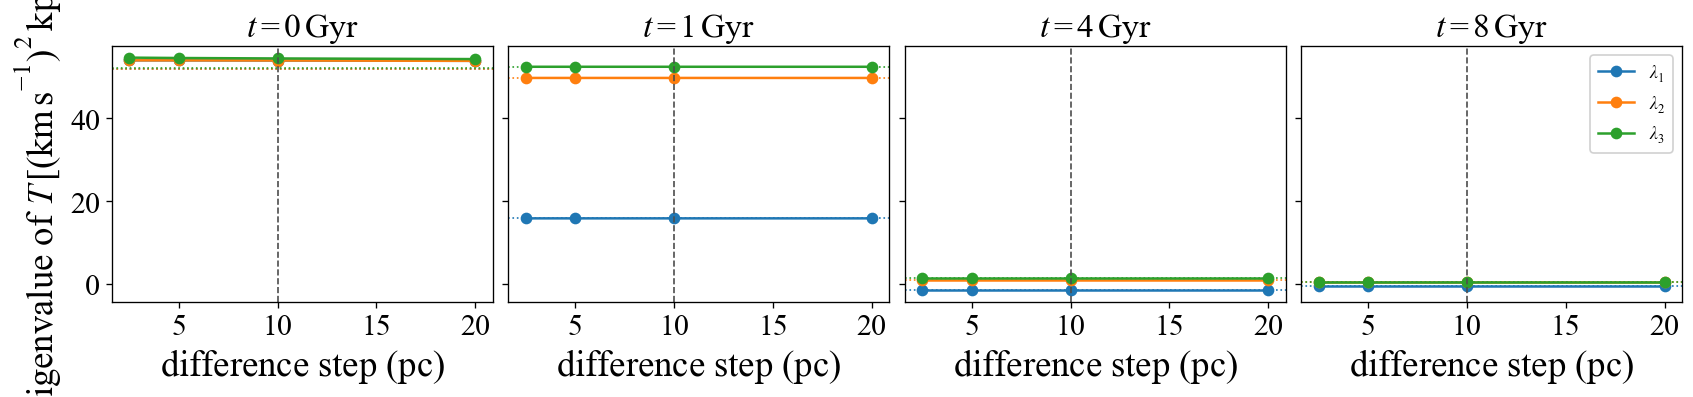

In [5]:
test_indices = [0, 10, 40, 80]
steps = np.array([0.0025, 0.005, 0.01, 0.02])
convergence = np.empty((len(test_indices), len(steps), 3))
analytic_eigenvalues = np.empty((len(test_indices), 3))
for a, index in enumerate(test_indices):
    analytic_eigenvalues[a] = np.linalg.eigvalsh(
        agama_tidal_tensor(centers["20pc"][index], time_gyr[index])
    )
    for b, step in enumerate(steps):
        convergence[a, b] = np.linalg.eigvalsh(
            force_difference_tidal_tensor(centers["20pc"][index], time_gyr[index], step)
        )

fig, axes = plt.subplots(1, len(test_indices), figsize=(14, 3.2), sharey=True, constrained_layout=True)
for panel, (ax, index, values) in enumerate(zip(axes, test_indices, convergence)):
    for eig_index in range(3):
        ax.plot(steps * 1e3, values[:, eig_index], "o-", label=rf"$\lambda_{eig_index+1}$")
        ax.axhline(analytic_eigenvalues[panel, eig_index], color=f"C{eig_index}", ls=":", lw=1)
    ax.axvline(FD_STEP_KPC * 1e3, color="0.3", ls="--", lw=1)
    ax.set(title=fr"$t={time_gyr[index]:g}\,\mathrm{{Gyr}}$", xlabel=r"difference step $(\mathrm{pc})$")
axes[0].set_ylabel(r"eigenvalue of $T\, [ (\mathrm{km\,s^{-1}})^2\,\mathrm{kpc}^{-2} ]$")
axes[-1].legend(loc="best", frameon=True, framealpha=0.9, fontsize=11)
plt.show()

## Measured $T_{ij}(t)$

A negative eigenvalue of $T$ is an extensive direction because the relative acceleration is $-T\xi$. All three initial-size runs use the same halo realization, but their finite tracer samples acquire slightly different center-of-mass paths.

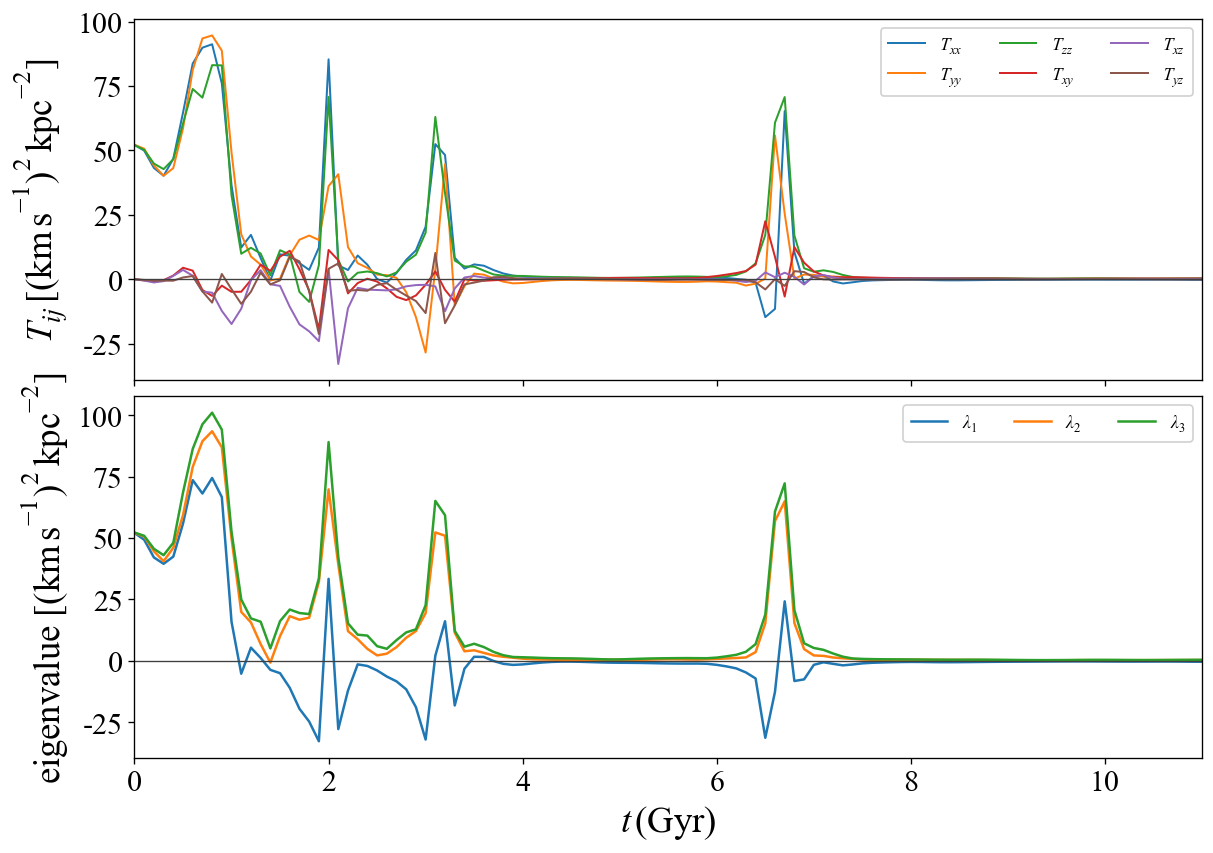

20 pc run: fraction of snapshots with each ordered eigenvalue < 0: [0.82882883 0.00900901 0.        ]


In [6]:
center_array = np.stack([centers[label] for label in LABELS])
tensor_array = np.empty((len(LABELS), NOUTPUT, 3, 3))
for case_index in range(len(LABELS)):
    derivatives = evolving_potential.eval(
        center_array[case_index], t=time_gyr / 0.978, der=True
    )
    tensor_array[case_index] = derivatives_to_tidal(derivatives)
tensors = {label: tensor_array[i] for i, label in enumerate(LABELS)}
np.savez_compressed(
    'tidal_tensor_ma1e-22_s0_results.npz', time_gyr=time_gyr,
    labels=np.array(LABELS), centers_kpc=center_array,
    tensor_kms2_kpc2=tensor_array,
)

T = tensors['20pc']
eigenvalues = np.linalg.eigvalsh(T)
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                         constrained_layout=True)
component_labels = {
    (0, 0): r'$T_{xx}$', (1, 1): r'$T_{yy}$', (2, 2): r'$T_{zz}$',
    (0, 1): r'$T_{xy}$', (0, 2): r'$T_{xz}$', (1, 2): r'$T_{yz}$',
}
for (i, j), label in component_labels.items():
    axes[0].plot(time_gyr, T[:, i, j], lw=1.2, label=label)
for i in range(3):
    axes[1].plot(time_gyr, eigenvalues[:, i], lw=1.5,
                 label=rf'$\lambda_{i+1}$')
axes[0].set_ylabel(
    r'$T_{ij}\, [ (\mathrm{km\,s^{-1}})^2\,\mathrm{kpc}^{-2} ]$')
axes[1].set(
    ylabel=r'eigenvalue $[ (\mathrm{km\,s^{-1}})^2\,\mathrm{kpc}^{-2} ]$',
    xlabel=r'$t\, (\mathrm{Gyr})$')
for axis in axes:
    axis.axhline(0, color='0.25', lw=0.8)
    axis.set_xlim(0, 11)
    axis.margins(x=0)
    axis.legend(loc='best', ncol=3, frameon=True, framealpha=0.9,
                fontsize=11)
plt.show()
print('20 pc run: fraction of snapshots with each ordered eigenvalue < 0:',
      np.mean(eigenvalues < 0, axis=0))


## Local tidal evolution versus the full multipole integration

The same saved initial positions and center-of-mass-subtracted velocities are evolved with the measured, linearly interpolated tensor. A kick-drift-kick scheme with 20 substeps per 0.1 Gyr potential interval is used. No fitted force amplitude or growth rate enters this calculation.

Plot configuration:
  FDM particle mass: m_a = 1.00e-22 eV
  Tracer particle mass: 0 (massless test particles)
  Initial projected half-light radii: 5, 10, 20 pc
  Soliton radius: 3.42174 kpc
  Evolution interval: 0-11 Gyr


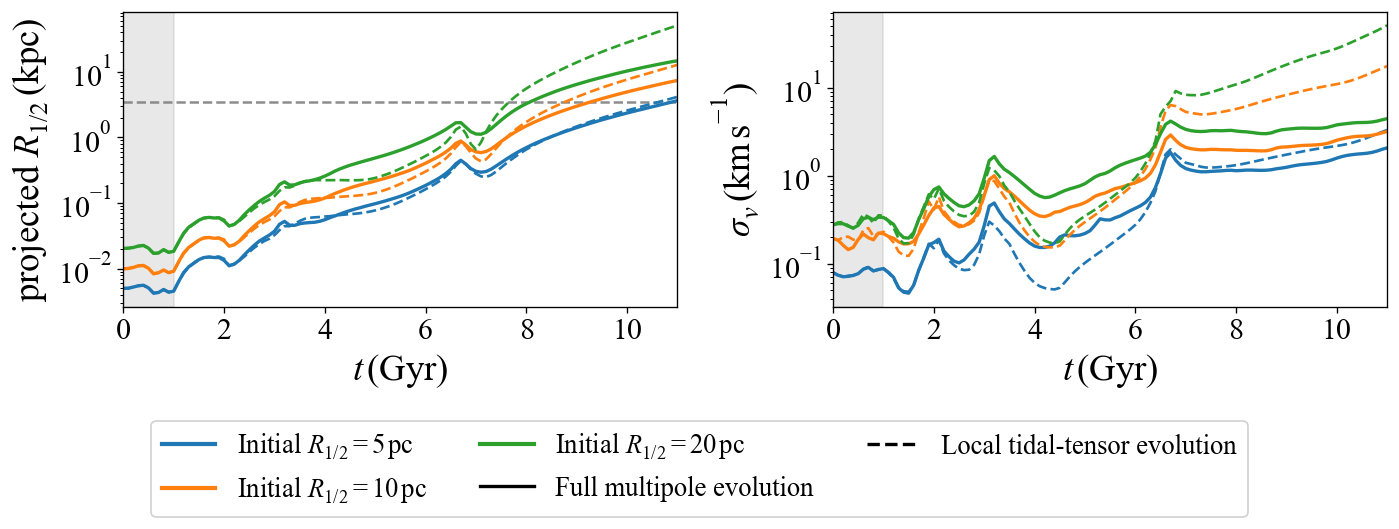

In [7]:
linear = {}
diagnostics = {}
for label in LABELS:
    initial_position = xvta[label][0, :3].T
    initial_velocity = xvta[label][0, 3:].T
    initial_velocity -= initial_velocity.mean(axis=0)
    linear[label] = evolve_local_tides(
        initial_position, initial_velocity, tensors[label], DT_GYR, substeps=20
    )
    diagnostics[label] = {
        'full': cluster_diagnostics(xvta[label]),
        'linear': cluster_diagnostics(linear[label]),
    }

colors = {'5pc': '#1f77b4', '10pc': '#ff7f0e', '20pc': '#2ca02c'}
radius_labels = {
    '5pc': r'Initial $R_{1/2}=5\,\mathrm{pc}$',
    '10pc': r'Initial $R_{1/2}=10\,\mathrm{pc}$',
    '20pc': r'Initial $R_{1/2}=20\,\mathrm{pc}$',
}
m_a = 1e-22
halo_mass = 1e9
r_setup = np.logspace(-3, 3, 512)
a = 10.0
alpha = 1.0 / 3.0
rho_nfw = (halo_mass / (2.0 * np.pi * a**3) / (r_setup / a)
           / (1.0 + r_setup / a) ** 3)
r_core = 1.6 * (m_a / 1e-22) ** -1 * (halo_mass / 1e9) ** (-alpha)
rho_soliton = (0.019 * (m_a / 1e-22) ** -2 * r_core**-4
                / (1.0 + 0.091 * (r_setup / r_core) ** 2) ** 8 * 1e9)
soliton_radius = r_setup[np.max(np.where(rho_soliton > rho_nfw)) + 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for label in LABELS:
    radius_full, sigma_full = diagnostics[label]['full']
    radius_linear, sigma_linear = diagnostics[label]['linear']
    axes[0].semilogy(time_gyr, radius_full, color=colors[label], lw=2)
    axes[0].semilogy(time_gyr, radius_linear, color=colors[label],
                     lw=1.6, ls='--')
    axes[1].semilogy(time_gyr, sigma_full, color=colors[label], lw=2)
    axes[1].semilogy(time_gyr, sigma_linear, color=colors[label],
                     lw=1.6, ls='--')
axes[0].axhline(soliton_radius, color='gray', ls='--', lw=1.5,
                alpha=0.9, zorder=1)
axes[0].set(xlabel=r'$t\, (\mathrm{Gyr})$',
            ylabel=r'projected $R_{1/2}\, (\mathrm{kpc})$')
axes[1].set(xlabel=r'$t\, (\mathrm{Gyr})$',
            ylabel=r'$\sigma_v\, (\mathrm{km\,s^{-1}})$')
for axis in axes:
    axis.axvspan(0, 1, color='gray', alpha=0.18, zorder=0)
    axis.set_xlim(0, 11)
    axis.margins(x=0)
radius_handles = [
    plt.Line2D([0], [0], color=colors[label], lw=2.5,
               label=radius_labels[label]) for label in LABELS
]
method_handles = [
    plt.Line2D([0], [0], color='black', lw=2,
               label='Full multipole evolution'),
    plt.Line2D([0], [0], color='black', lw=2, ls='--',
               label='Local tidal-tensor evolution'),
]
fig.legend(handles=radius_handles + method_handles, loc='lower center',
           bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=16,
           frameon=True, framealpha=0.9)
# Use one fixed rectangle for both panels so their plotting areas match exactly.
fig.subplots_adjust(left=0.10, right=0.99, bottom=0.38, top=0.98,
                    wspace=0.18)
fig.savefig(FIGURES_DIR / 'tidal_local_evolution.png', dpi=300, bbox_inches='tight')
print('Plot configuration:')
print('  FDM particle mass: m_a = 1.00e-22 eV')
print('  Tracer particle mass: 0 (massless test particles)')
print('  Initial projected half-light radii: 5, 10, 20 pc')
print(f'  Soliton radius: {soliton_radius:.6g} kpc')
print('  Evolution interval: 0-11 Gyr')
plt.show()


In [8]:
fit_mask = (time_gyr >= 1.0) & (time_gyr <= 4.0)
index4 = np.argmin(abs(time_gyr - 4.0))
print("Early-phase comparison (fit interval 1-4 Gyr)")
print("R_ic   k_R full   k_R local   R_local/R_full at 4 Gyr")
for label in LABELS:
    radius_full = diagnostics[label]["full"][0]
    radius_linear = diagnostics[label]["linear"][0]
    k_full = np.polyfit(time_gyr[fit_mask], np.log(radius_full[fit_mask]), 1)[0]
    k_linear = np.polyfit(time_gyr[fit_mask], np.log(radius_linear[fit_mask]), 1)[0]
    ratio4 = radius_linear[index4] / radius_full[index4]
    print(f"{label:>4s}   {k_full:8.3f}   {k_linear:9.3f}   {ratio4:10.3f}")

print(f"\nLate-time ratio R_local/R_full at {time_gyr[-1]:.3f} Gyr:")
for label in LABELS:
    ratio = diagnostics[label]["linear"][0][-1] / diagnostics[label]["full"][0][-1]
    print(f"{label:>4s}: {ratio:7.2f}")

Early-phase comparison (fit interval 1-4 Gyr)
R_ic   k_R full   k_R local   R_local/R_full at 4 Gyr
 5pc      0.748       0.775        1.118
10pc      0.764       0.765        0.997
20pc      0.781       0.748        0.867

Late-time ratio R_local/R_full at 11.000 Gyr:
 5pc:    1.14
10pc:    1.73
20pc:    3.48


## Interpretation

Using the directly saved center of mass and AGAMA's own force derivatives changes the quantitative conclusion. The local equation produces correlated expansion episodes and a persistent extensive eigen-direction, but over 1--4 Gyr it gives $k_R\simeq0.47\,\mathrm{Gyr}^{-1}$ compared with $0.72$--$0.76\,\mathrm{Gyr}^{-1}$ in the full integration; at 4 Gyr its radius is only $47$--$49\%$ of the full result. Thus this run supports a tidal contribution but does **not** yet demonstrate quantitative reproduction by the strictly linear local equation.

The remaining difference could come from higher spatial derivatives once the tracer expands, finite temporal sampling of the tensor, or details of defining a center for a strongly distorted tracer. These should be separated before making a paper-level reproduction claim. Spatial convergence must also be tested by regenerating the potential with different radial grids, angular truncations, and interpolation orders.